In [255]:
import numpy as np 
import pandas as pd 

In [256]:
df=pd.read_csv('Ice_cream selling data.csv')
cdf=df

In [257]:
cdf.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [258]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (°C)         49 non-null     float64
 1   Ice Cream Sales (units)  49 non-null     float64
dtypes: float64(2)
memory usage: 916.0 bytes


In [259]:
cdf.isna().sum()

Temperature (°C)           0
Ice Cream Sales (units)    0
dtype: int64

In [260]:
from sklearn.linear_model import LinearRegression
X=cdf[['Temperature (°C)']]
Y=cdf['Ice Cream Sales (units)']

In [261]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.20)

Model=LinearRegression()
Model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


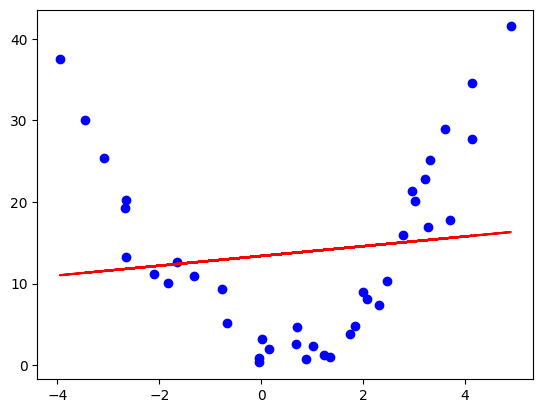

In [262]:
import matplotlib.pyplot as plt
plt.scatter(x_train,y_train,color='blue')
plt.plot(x_train,Model.predict(x_train),color='red')


In [263]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
def poly_model(degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree,include_bias=False)),
        ("Scaler",StandardScaler()),
        ("model",LinearRegression())
    ])

In [275]:
pipeline=poly_model(degree=0)

param_grid={
    "poly__degree":list(range(1,11)),
}

grid=GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error'
    )

grid.fit(x_train,y_train)

print("Best_Degree :",grid.best_params_)
print("R2 :",-grid.best_score_)

Best_Degree : {'poly__degree': 2}
R2 : 2.991091309565036


In [271]:
from sklearn.metrics import mean_squared_error,mean_absolute_error 

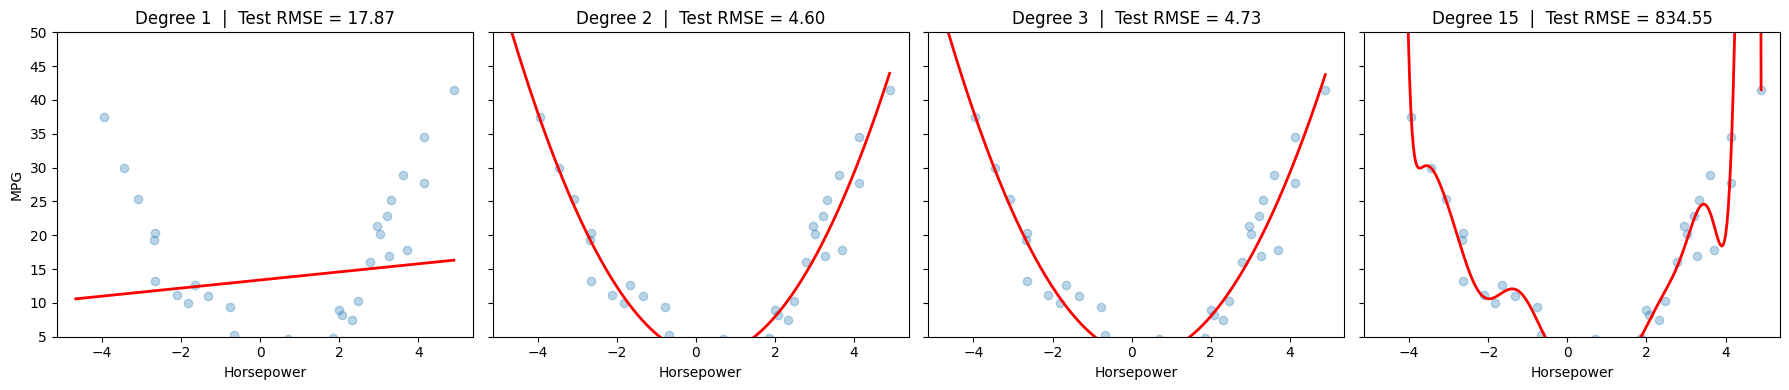

In [274]:
degrees_to_show = [1, 2, 3, 15]
x_range = pd.DataFrame({"Temperature (°C)": np.linspace(X["Temperature (°C)"].min(), X["Temperature (°C)"].max(), 300)})

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, d in zip(axes, degrees_to_show):
    model = poly_model(d)
    model.fit(x_train, y_train)
    test_rmse = np.sqrt(mean_squared_error(y_test, model.predict(x_test)))

    ax.scatter(x_train, y_train, alpha=0.3)
    ax.plot(x_range, model.predict(x_range), color="red", linewidth=2)
    ax.set_title(f"Degree {d}  |  Test RMSE = {test_rmse:.2f}")
    ax.set_xlabel("Horsepower")
    ax.set_ylim(5, 50)
axes[0].set_ylabel("MPG")
plt.tight_layout()
plt.show()

In [272]:
results = pd.DataFrame({
    "degree": grid.cv_results_["param_poly__degree"],
    "cv_rmse": -grid.cv_results_["mean_test_score"],
    "std_across_folds": grid.cv_results_["std_test_score"],
}).round(3)
results

,degree,cv_rmse,std_across_folds
0,1,12.124,2.771
1,2,2.991,0.661
2,3,3.080,0.643
3,4,3.232,0.777
4,5,3.400,1.121
5,6,4.308,1.875
6,7,6.250,5.182
7,8,6.643,6.463
8,9,18.171,27.515
9,10,49.119,56.359


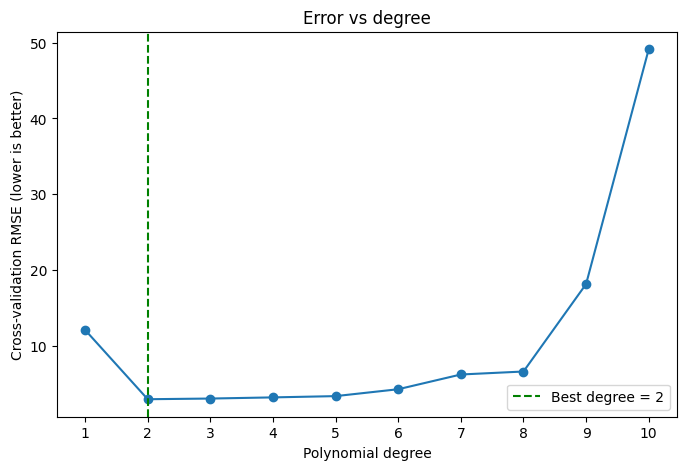

In [273]:
plt.figure(figsize=(8, 5))
plt.plot(results["degree"], results["cv_rmse"], marker="o")
best_d = grid.best_params_["poly__degree"]
plt.axvline(best_d, color="green", linestyle="--", label=f"Best degree = {best_d}")
plt.xlabel("Polynomial degree")
plt.ylabel("Cross-validation RMSE (lower is better)")
plt.title("Error vs degree")
plt.xticks(results["degree"])
plt.legend()
plt.show()